# PCA on preprocessed data


    Imports

In [28]:
import numpy as np
import scanpy as sc
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

Data loading

In [29]:
adata = sc.read_h5ad("../Data/preprocessed.h5ad")

adata

adata.obsm["X_pca"].shape

# X = adata.layers["log_normalized"]
X = adata[:, adata.var["highly_variable"]].layers["log_normalized"]

if not isinstance(X, np.ndarray):
    X = X.toarray()

PCA

In [30]:
pca = PCA(n_components=50)
pca.fit(X)

X_pca = pca.transform(X)

# Variance expliquée par chaque composante
print(pca.explained_variance_ratio_)

# Variance expliquée cumulée
print(np.cumsum(pca.explained_variance_ratio_))

# Contributions des variables (loadings)
print(pca.components_)

[0.15136811 0.05230638 0.05021866 0.03599127 0.02743894 0.01341754
 0.01217537 0.01008008 0.00986258 0.0085297  0.00793717 0.00719901
 0.00608791 0.00563134 0.005505   0.00475314 0.00458465 0.00415756
 0.00381692 0.00341326 0.00338817 0.00325189 0.00301609 0.00299633
 0.00268564 0.0026346  0.00254243 0.00246756 0.00242474 0.00228587
 0.0022481  0.00211492 0.00207621 0.0020259  0.00197059 0.00193826
 0.00187653 0.0018202  0.00178489 0.00174812 0.00173622 0.00171738
 0.00167283 0.00166097 0.00160039 0.00157269 0.00152278 0.00149819
 0.00146665 0.0014302 ]
[0.15136811 0.2036745  0.25389317 0.28988445 0.3173234  0.33074093
 0.3429163  0.35299638 0.36285895 0.37138864 0.3793258  0.38652483
 0.39261273 0.39824408 0.40374908 0.40850222 0.41308686 0.41724443
 0.42106137 0.42447463 0.4278628  0.43111467 0.43413076 0.43712708
 0.43981272 0.4424473  0.44498974 0.44745728 0.44988203 0.4521679
 0.454416   0.45653093 0.45860714 0.46063304 0.46260363 0.46454188
 0.46641842 0.46823862 0.4700235  0.471

PCA Visualsation

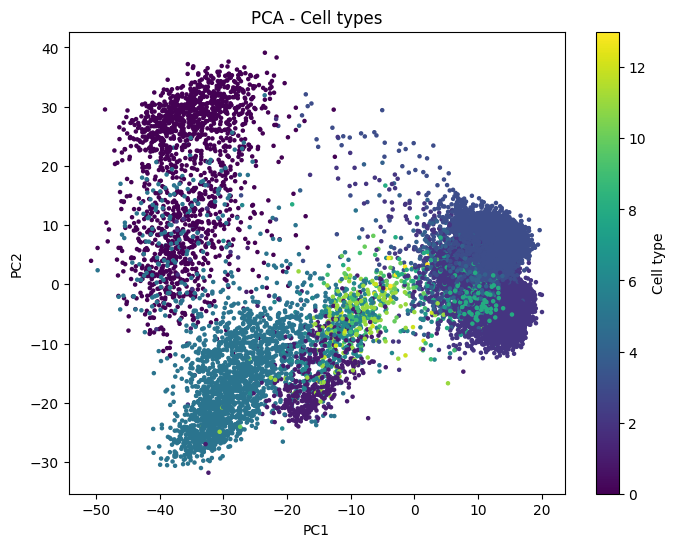

In [31]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=adata.obs["celltype"].astype("category").cat.codes,
    cmap="viridis",
    s=5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Cell types")
plt.colorbar(label="Cell type")
plt.show()

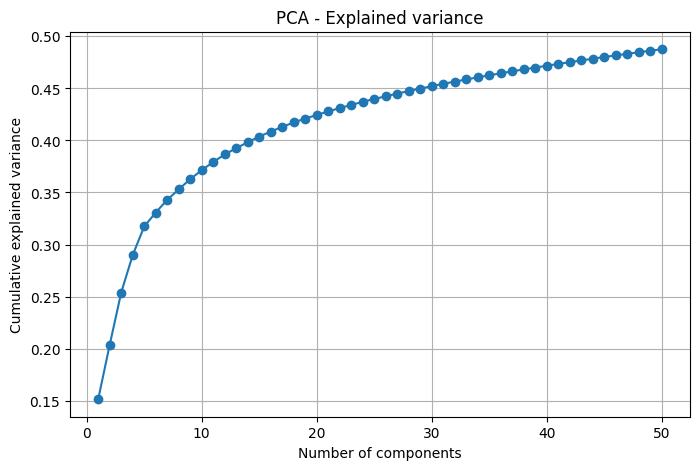

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 51),
    np.cumsum(pca.explained_variance_ratio_),
    marker="o"
)

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA - Explained variance")
plt.grid()
plt.show()

Data reconstruction

In [38]:
X_reconstructed = pca.inverse_transform(X_pca)

Reconstructed_pca = pca.transform(X_reconstructed)

Reconstructed data visualisation

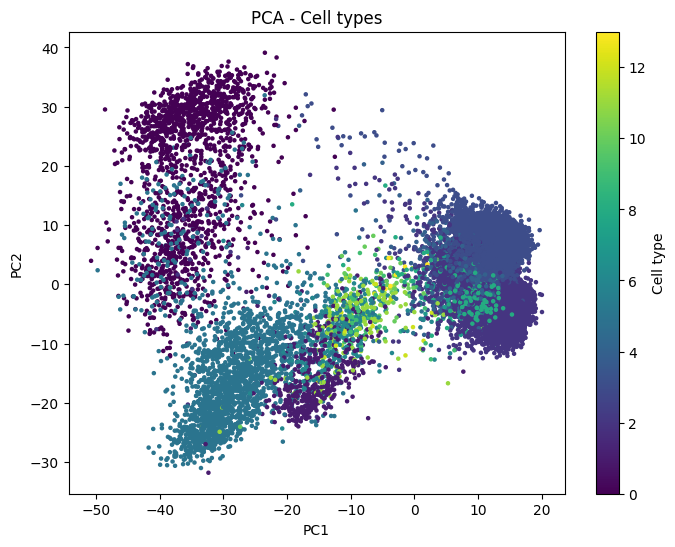

In [39]:
plt.figure(figsize=(8, 6))

plt.scatter(
    Reconstructed_pca[:, 0],
    Reconstructed_pca[:, 1],
    c=adata.obs["celltype"].astype("category").cat.codes,
    cmap="viridis",
    s=5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Cell types")
plt.colorbar(label="Cell type")
plt.show()

Text(0.5, 1.0, 'Original vs Reconstructed')

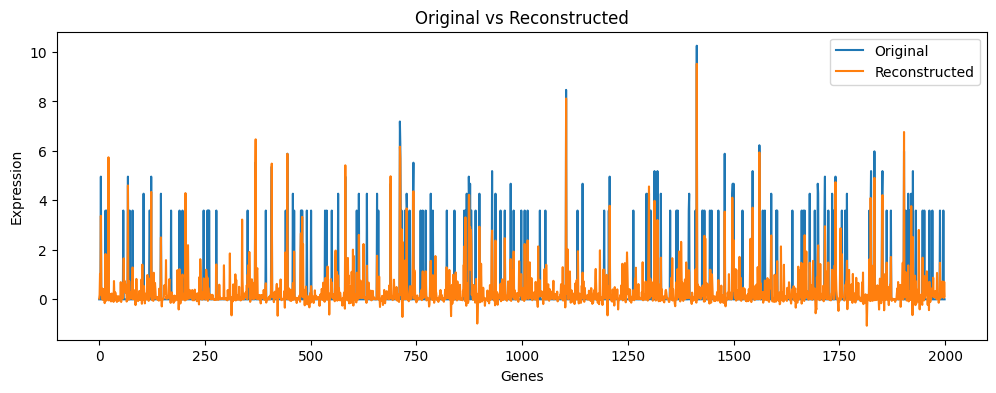

In [35]:
plt.figure(figsize=(12, 4))

plt.plot(X[0], label="Original")
plt.plot(X_reconstructed[0], label="Reconstructed")

plt.legend()
plt.xlabel("Genes")
plt.ylabel("Expression")
plt.title("Original vs Reconstructed")

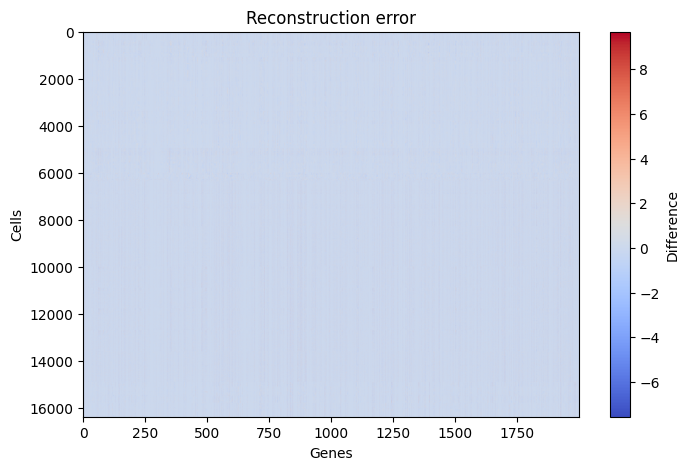

In [36]:
plt.figure(figsize=(8, 5))

plt.imshow(X - X_reconstructed, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Difference")

plt.xlabel("Genes")
plt.ylabel("Cells")
plt.title("Reconstruction error")

plt.show()

Reconstruction evaluation

In [37]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(X, X_reconstructed)

print("Reconstruction error:", mse)

Reconstruction error: 0.606993556022644
